In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.formula.api as smf

import pickle
import os

### Question 1
- How quickly does inactivity turn into churn?
Churn rises steadily with days since last login. In a rough cut, about 60% of customers who logged in within 30 days churned, versus about 91% of those inactive for 150+ days. A good question is whether there’s a threshold, say 60 or 90 days, where risk jumps. That would give a concrete trigger for a win-back campaign.

In [2]:
dataset = '../data/customer_churn_clean.csv'
result_dir = '../result'

df = pd.read_csv(dataset)
df.head()

,Unnamed: 0,customer_id,gender,region,subscription_plan,payment_method,age,days_since_last_login,customer_service_calls,monthly_spend,churn
0,0,10001,Male,East,Basic,PayPal,27.0,27,1.0,61.08,0
1,1,10002,NaN,West,Pro,PayPal,55.0,146,2.0,73.09,0
2,2,10003,Female,West,Pro,E-Wallet,NaN,147,2.0,116.30,1
3,3,10004,Female,South,Basic,Credit Card,NaN,34,1.0,0.58,1
4,4,10005,Male,North,Basic,Crypto,30.0,146,3.0,46.35,1


#### Analysis Variables
* days_since_last_login
    - time (in days) since last login
* churn
    - target variable; 
        - 1 = churned
        - 2 = retained

In [3]:
# Subsetting the dataset with only required variables
# Dropping null values for logistic regression analysis

inactivity_churn = df[['days_since_last_login','churn']].dropna()
inactivity_churn.head()

,days_since_last_login,churn
0,27,0
1,146,0
2,147,1
3,34,1
4,146,1


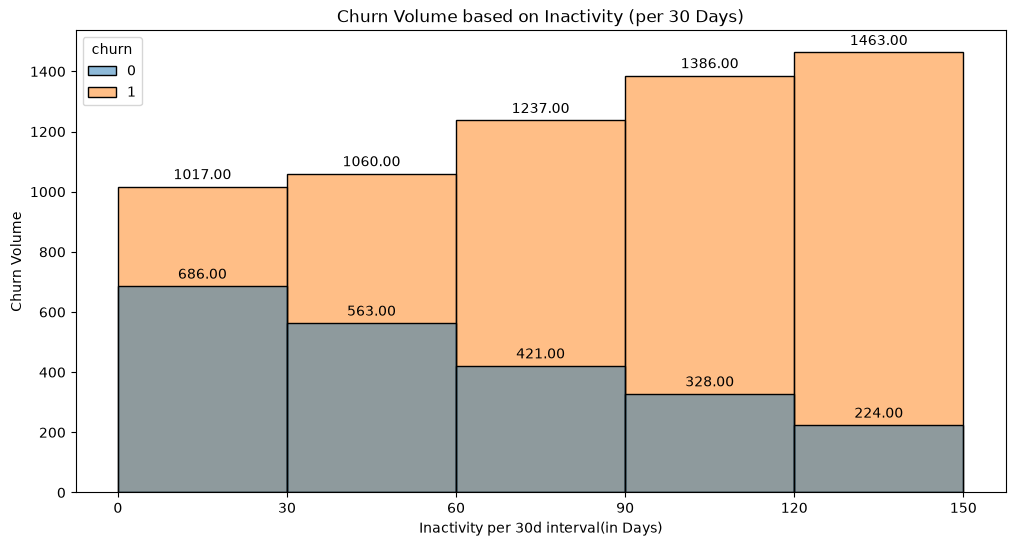

In [4]:
# Visualizing churn per inactivity (30d)

fig, ax = plt.subplots(figsize=(12,6))
max_days = inactivity_churn.days_since_last_login.max()
bins = np.arange(0,max_days,30)

p = sns.histplot(
    x = inactivity_churn.days_since_last_login,
    hue=inactivity_churn.churn,
    bins=bins,
    ax=ax
)

for p in p.patches:
    height=p.get_height()
    ax.annotate(
        f'{height:.2f}',
        xy=(p.get_x()+p.get_width()/2,height),
        xytext=(0,3),
        textcoords='offset points',
        ha='center', va='bottom'
    )
plt.xticks(np.arange(0, max_days,30))
plt.xlabel('Inactivity per 30d interval(in Days)')
plt.ylabel('Churn Volume')
plt.title('Churn Volume based on Inactivity (per 30 Days)')
plt.show()

**_Churn Volume based on Inactivity (30d Interval)_**

The plot shows that as the period of inactivity increases, the volume or proportion of churned users grows.

For every 30 Days interval, the number of churns increases by approx. 200 customers.

In [5]:
# Converting days_since_last_login to categorical variables
# Category: 30d interval

def days_interval(days):
    if days in range(0,31):
        return '30d'
    if days in range(31,61):
        return '60d'
    if days in range(61,91):
        return '90d'
    if days in range(91,121):
        return '120d'
    if days in range(121,151):
        return '150d'
    if days in range(151,181):
        return '180d'

# ordered inactivity
days_order = [
    '30d','60d','90d','120d','150d','180d'
]
inactivity_churn['inactivity'] = inactivity_churn.days_since_last_login.apply(days_interval)
inactivity_churn.inactivity = pd.Categorical(inactivity_churn.inactivity, categories=days_order, ordered=True)
inactivity_churn.head()

,days_since_last_login,churn,inactivity
0,27,0,30d
1,146,0,150d
2,147,1,150d
3,34,1,60d
4,146,1,150d


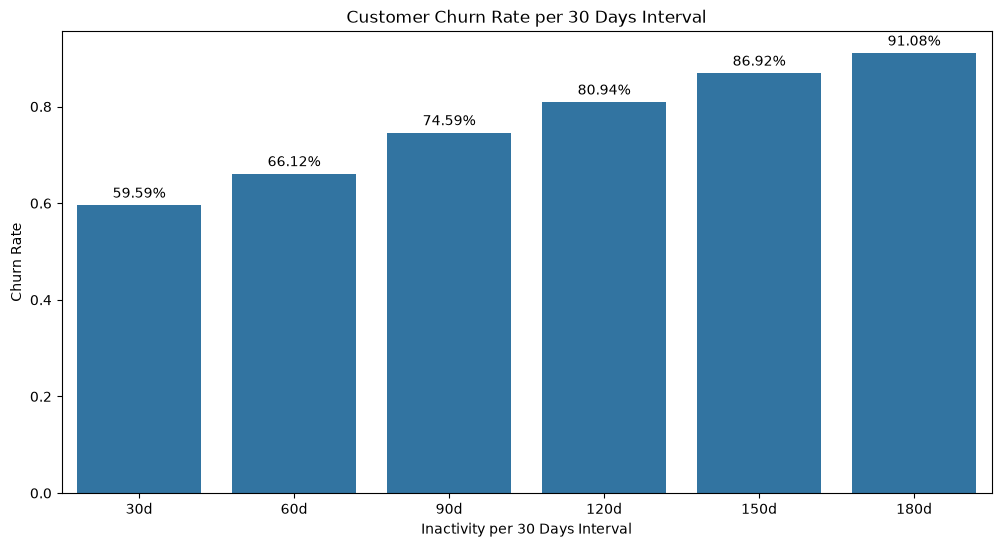

In [6]:
# Visualizing churn per 30days
fig, ax = plt.subplots(figsize=(12,6))
p = sns.barplot(
    x = 'inactivity',
    y = 'churn',
    data = inactivity_churn,
    ax = ax,
    errorbar=None
)
for p in p.patches:
    height=p.get_height()
    ax.annotate(
        f'{height*100:.2f}%',
        xy=(p.get_x()+p.get_width()/2, height),
        xytext=(0,3),
        textcoords='offset points',
        ha='center',
        va='bottom'
    )
plt.xlabel('Inactivity per 30 Days Interval')
plt.ylabel('Churn Rate')
plt.title('Customer Churn Rate per 30 Days Interval')
plt.show()

**_Customer Churn Rate per 30 Days Interval_**

The plot shows that for every 30 Days increase in inactivity, the churn rate increases - supporting the findings from **_Churn Volume based on Inactivity (30d Interval)_** plot.

#### Performing Hypothesis Testing in Logistic Regression and Results Analysis

$H_0$ = The regression coefficient ($β_r$) = 0 
        Customer inactivity has no effect on the log-odds (probability) of customer churn

$H_1$ = The regression coefficient ($β_r$) != 0
        Customer inactivity has effect on the log-odds (probability) of customer churn

In [7]:
# Creating formula
formula = "churn ~ C(inactivity)"

# Modeling logit regression
model = smf.logit(formula, data=inactivity_churn).fit()

# Summary Analysis/Interpretation
summary = model.summary()
summary


Optimization terminated successfully.
         Current function value: 0.511857
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  churn   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9994
Method:                           MLE   Df Model:                            5
Date:                Tue, 27 Oct 2026   Pseudo R-squ.:                 0.06447
Time:                        16:55:44   Log-Likelihood:                -5118.6
converged:                       True   LL-Null:                       -5471.3
Covariance Type:            nonrobust   LLR p-value:                3.260e-150
=========================================================================================
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                 0.3884      0.049      7.977      0.000       0.293       0.484
C(inactivity)[T.60d]      0.2801      0.071      3.922      0.000       0.140       0.420
C(inactivity)[T.90d]      0.6886      0.075      9.240      0.000       0.543       0.835
C(inactivity)[T.120d]     1.0576      0.079     13.463      0.000       0.904       1.212
C(inactivity)[T.150d]     1.5055      0.088     17.105      0.000       1.333       1.678
C(inactivity)[T.180d]     1.9355      0.100     19.360      0.000       1.740       2.131
=========================================================================================
"""

**_Logit Regression Results_**

Inactivity interval shows a positive gradual increase of customer churn. The p-values of `0.00` indicates a very strong positive significanct relationship with the raw coefficients of churn

#### Results Inverse Transformation
- Odds Ratio :  Multiplicative effect on the odds.
    * $Odds_r$ < 1 : Negative relationship
    * $Odds_r$ = 1 : No relationship
    * $Odds_r$ > 1 : Positive relashionship

- % Change in Odds : increase/decrease percent on the odds
- Total Odds : Combined odds of the event occurring for that specific profile.
- Predicted Risk : Final probability of that outcome occuring

In [8]:
def get_oddsratio(model_obj):
    params = model_obj.params.drop('Intercept',)
    intercept = model_obj.params.iloc[0]

    
    odds_df = pd.DataFrame({
        'Coef': params,
        'Odds Ratio':np.exp(params),
        r"% Change in Odds":(np.exp(params)-1)*100,
        'Total Odds':np.exp(params+intercept),
        'Predicted Risk':round(np.exp(params + intercept)/(1 + np.exp(params + intercept))*100, 2).astype(str)+'%'
    })

    intercept_df = pd.DataFrame({
        'Coef':[intercept],
        'Odds Ratio': ["---"],
        r"% Change in Odds": ["---"],
        'Total Odds' : [np.exp(intercept)],
        'Predicted Risk' : [round(np.exp(intercept)/(1+np.exp(intercept))*100,2).astype(str)+'%']
    }, index = ['C(inactivity)[T.30d]'])
    result_df = pd.concat([intercept_df,odds_df])
    return result_df

logReg_churn_inactivity = get_oddsratio(model)
logReg_churn_inactivity

,Coef,Odds Ratio,% Change in Odds,Total Odds,Predicted Risk
C(inactivity)[T.30d],0.388371,---,---,1.474576,59.59%
C(inactivity)[T.60d],0.280106,1.323271,32.327068,1.951264,66.12%
C(inactivity)[T.90d],0.688632,1.99099,99.099025,2.935867,74.59%
C(inactivity)[T.120d],1.057643,2.879576,187.95756,4.246154,80.94%
C(inactivity)[T.150d],1.505473,4.506284,350.628424,6.644860,86.92%
C(inactivity)[T.180d],1.935514,6.927602,592.760217,10.215278,91.08%


In [9]:
# Saving results
results_path = 'result/'
def save_result(result_name:str, result):
    os.makedirs('result', exist_ok=True)

    with open(results_path+result_name+'.pickle', 'wb') as to_write:
        pickle.dump(result, to_write)

save_result('inactivity_churn_analysis_results', model)

**_Inverse Transformation Results Analysis_**
1. The predicted risks computed from the **_Logit Regression Results_** aligns with the calculated churn rate from **_Customer Churn Rate per 30 Days Interval_** plot.

2. 30 Days inactivity shows a high baseline risk of churn, this suggests that 1 of 2 customers will churn. At 90 Days Inactivity shows the highest risk increase and have an odds ratio where churn risk accelerate significantly. Setting for higher inactivity than 60 Days means communicating to customer who have 2 or more times more chances of churning 

**_Hypothesis Decision_**
- Reject the null hypothesis ($H_0$)
- Customer inactivity has a positive effect on the log-odds (probability) of customer churn

**_Conclusion_**
- The result of the analysis shows that customer inactivity has a positive relationship with churn rate.
- Given the odds and predicted risks per inactivity interval, a 30d inactivity is the ideal threshold for escalating customer re-engagement. The baseline churn rate is already high, thus setting for higher inactivity will miss few custmoers for re-engagement.